# CNN для Fashion MNIST

In [8]:
# %pip install "kagglehub[pandas-datasets]" tensorflow matplotlib

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from kagglehub import KaggleDatasetAdapter
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

def load_data(filename):
    df = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        "zalando-research/fashionmnist/versions/4",
        filename,
        pandas_kwargs={"dtype": np.uint8},
    )
    labels = df.pop("label").to_numpy()
    images = df.to_numpy(dtype=np.float32).reshape(-1, 28, 28, 1) / 255
    return images, labels

x, y = load_data("fashion-mnist_train.csv")
x_test, y_test = load_data("fashion-mnist_test.csv")

indices = np.random.default_rng(42).permutation(len(y))
x, y = x[indices], y[indices]

In [9]:
model = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 5, activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(32, 5, activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)
history = model.fit(
    x, y, validation_split=0.1, epochs=100, batch_size=64,
    callbacks=[early_stop], verbose=2,
)

Epoch 1/100
844/844 - 6s - 7ms/step - accuracy: 0.7399 - loss: 0.7198 - val_accuracy: 0.8368 - val_loss: 0.4323
Epoch 2/100
844/844 - 4s - 5ms/step - accuracy: 0.8288 - loss: 0.4736 - val_accuracy: 0.8580 - val_loss: 0.3722
Epoch 3/100
844/844 - 4s - 5ms/step - accuracy: 0.8496 - loss: 0.4139 - val_accuracy: 0.8737 - val_loss: 0.3345
Epoch 4/100
844/844 - 4s - 5ms/step - accuracy: 0.8607 - loss: 0.3853 - val_accuracy: 0.8818 - val_loss: 0.3191
Epoch 5/100
844/844 - 4s - 5ms/step - accuracy: 0.8675 - loss: 0.3662 - val_accuracy: 0.8858 - val_loss: 0.2989
Epoch 6/100
844/844 - 4s - 5ms/step - accuracy: 0.8717 - loss: 0.3524 - val_accuracy: 0.8907 - val_loss: 0.2928
Epoch 7/100
844/844 - 4s - 5ms/step - accuracy: 0.8749 - loss: 0.3436 - val_accuracy: 0.8922 - val_loss: 0.2835
Epoch 8/100
844/844 - 4s - 5ms/step - accuracy: 0.8794 - loss: 0.3327 - val_accuracy: 0.8927 - val_loss: 0.2862
Epoch 9/100
844/844 - 4s - 5ms/step - accuracy: 0.8811 - loss: 0.3277 - val_accuracy: 0.8955 - val_loss:

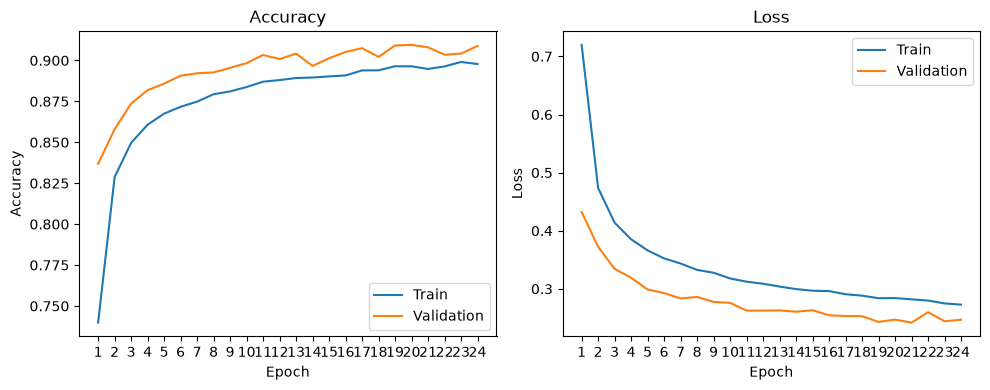

In [10]:
epochs = range(1, len(history.epoch) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric, title in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(epochs, history.history[metric], label="Train")
    ax.plot(epochs, history.history[f"val_{metric}"], label="Validation")
    ax.set(title=title, xlabel="Epoch", ylabel=title, xticks=list(epochs))
    ax.legend()

plt.tight_layout()
plt.show()

Test accuracy: 91.32%


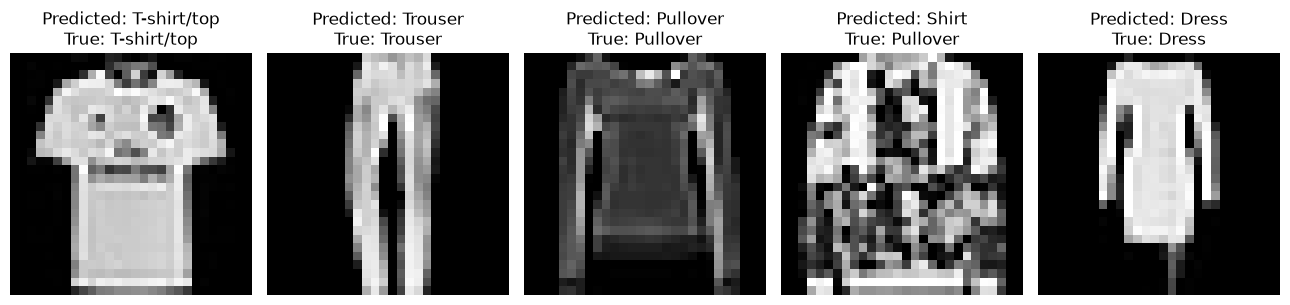

In [11]:
_, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy:.2%}")

classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
predictions = model.predict(x_test[:5], verbose=0).argmax(axis=1)

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, image, predicted, actual in zip(axes, x_test[:5], predictions, y_test[:5]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Predicted: {classes[predicted]}\nTrue: {classes[actual]}")
    ax.axis("off")
plt.tight_layout()
plt.show()